# Descrizione del dataset

Obiettivo di questa esercitazione è quello di creare un modello di regressione in grado di prevedere la quantità di energia prodotta da un impianto fotovoltaico. Il dataset è relativo a un impianto fotovoltaico reale di 960 kWP ubicato a Lecce. Il dataset:

- contiene circa 15000 record relativi a medie orarie su un periodo di poco meno di 2 anni (500 giorni);
-  la variabile **indipendente** è costituita dal vettore 6-dimensionale [Ora, Data, Temperatura ambiente, Temperatura dei moduli, Irraggiamento dei pannelli inclinati a 3 gradi, Irraggiamento dei pannelli inclinati a 15 gradi];
-  la **variabile dipendente** (valore *target*) è costituita dalla produzione in kWH dell'impianto in una determinata ora.

Di seguito vengono forniti i riferimenti per ulteriori approfondimenti:
- M. Malvoni, M. G. De Giorgi, P. M. Congedo, [*Data on photovoltaic powerforecasting models for Mediterranean climate*](https://www.sciencedirect.com/science/article/pii/S2352340916302773), Data in Brief, 2016.
- M. G. De Giorgi, M. Malvoni, P. M. Congedo, [*Comparison of strategies for multi-step ahead photovoltaic power forecasting models based on hybrid group method of data handling networks and least square support vector machine*](https://www.sciencedirect.com/science/article/abs/pii/S0360544216304261), Energy, 2016.

Link al download del dataset: [Dataset](http://bias.csr.unibo.it/maltoni/ml/Esercitazioni/Materiale/Dataset_Regressione.zip)

In [1]:
import numpy as np
import pandas as pd
import datetime as dt

from sklearn.linear_model import LinearRegression 
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV, TimeSeriesSplit

import matplotlib.pyplot as plt

In [2]:
filePath = './DBs/SolarPark/train.txt'

dataframe = pd.read_csv(filePath)
print(type(dataframe))

<class 'pandas.DataFrame'>


In [3]:
# Stampa di informazioni sulle features (colonne): cardinalità e tipo
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 7902 entries, 0 to 7901
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Time Frame  7902 non-null   int64  
 1   Date        7902 non-null   str    
 2   Ta (C)      7902 non-null   float64
 3   Tm (C)      7902 non-null   float64
 4   I3 (W/m2)   7902 non-null   float64
 5   I15 (W/m2)  7902 non-null   float64
 6   P (kW)      7902 non-null   float64
dtypes: float64(5), int64(1), str(1)
memory usage: 432.3 KB


In [4]:
# Stampa delle statistiche aggregate sulle features
dataframe.describe()

# Jupyter gestisce direttamente il risultato di describe() presentandolo adeguatamente
# Si noti la differenza di output decommentando la seguente riga:
#print(dataframe.describe())

,Time Frame,Ta (C),Tm (C),I3 (W/m2),I15 (W/m2),P (kW)
count,7902.000000,7902.000000,7902.000000,7902.000000,7902.000000,7902.000000
mean,12.492407,15.089675,17.755080,203.455206,214.903907,161.668209
std,6.917957,11.683758,16.641611,291.878650,306.698855,234.276655
min,1.000000,-1.460000,-7.130000,0.000000,0.000000,0.000000
25%,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,12.000000,15.535000,14.885000,8.545000,9.785000,4.295000
75%,18.000000,24.037500,28.637500,364.795000,380.785000,292.362500
max,24.000000,43.530000,70.140000,1031.550000,1051.230000,806.610000


In [5]:
dataframe
# shows some of the initial patterns and some of the final

,Time Frame,Date,Ta (C),Tm (C),I3 (W/m2),I15 (W/m2),P (kW)
0,16,3/5/12 4:55 PM,13.01,12.05,52.47,53.08,6.50
1,17,3/5/12 5:55 PM,11.81,8.50,10.41,10.95,0.01
2,18,3/5/12 6:55 PM,10.33,5.68,0.00,0.00,0.00
3,19,3/5/12 7:55 PM,9.66,4.67,0.00,0.00,0.00
4,20,3/5/12 8:55 PM,8.91,3.82,0.00,0.00,0.00
...,...,...,...,...,...,...,...
7897,2,2/1/13 9:45 PM,0.00,0.00,0.00,0.00,0.00
7898,3,2/1/13 9:45 PM,0.00,0.00,0.00,0.00,0.00
7899,4,2/2/13 4:55 AM,10.25,6.83,0.00,0.00,0.00
7900,5,2/2/13 5:55 AM,10.54,8.06,0.00,0.00,0.00


Essendo Pandas ampiamente utilizzato in ambito Machine Learning e Data Science, son disponibili *plugin* o customizzazioni di Jupyter per permettere un'esplorazione più interattiva dei dati. Ad esempio, Google Colaboratory offre [un'estensione ad hoc](https://twitter.com/GoogleColab/status/1190349318617583616) per trattare la visualizzazione di **DataFrame**.

Inoltre, la classe **DataFrame** offre la possibilità di visualizzare graficamente la distribuzione dei valori delle feature sotto forma di istogrammi. Attraverso la visualizzazione grafica della distribuzione dei valori è possibile individuare tra le varie cose anomalie e la presenza di dati mancanti.

La visualizzazione grafica è demandata alla libreria Matplotlib.

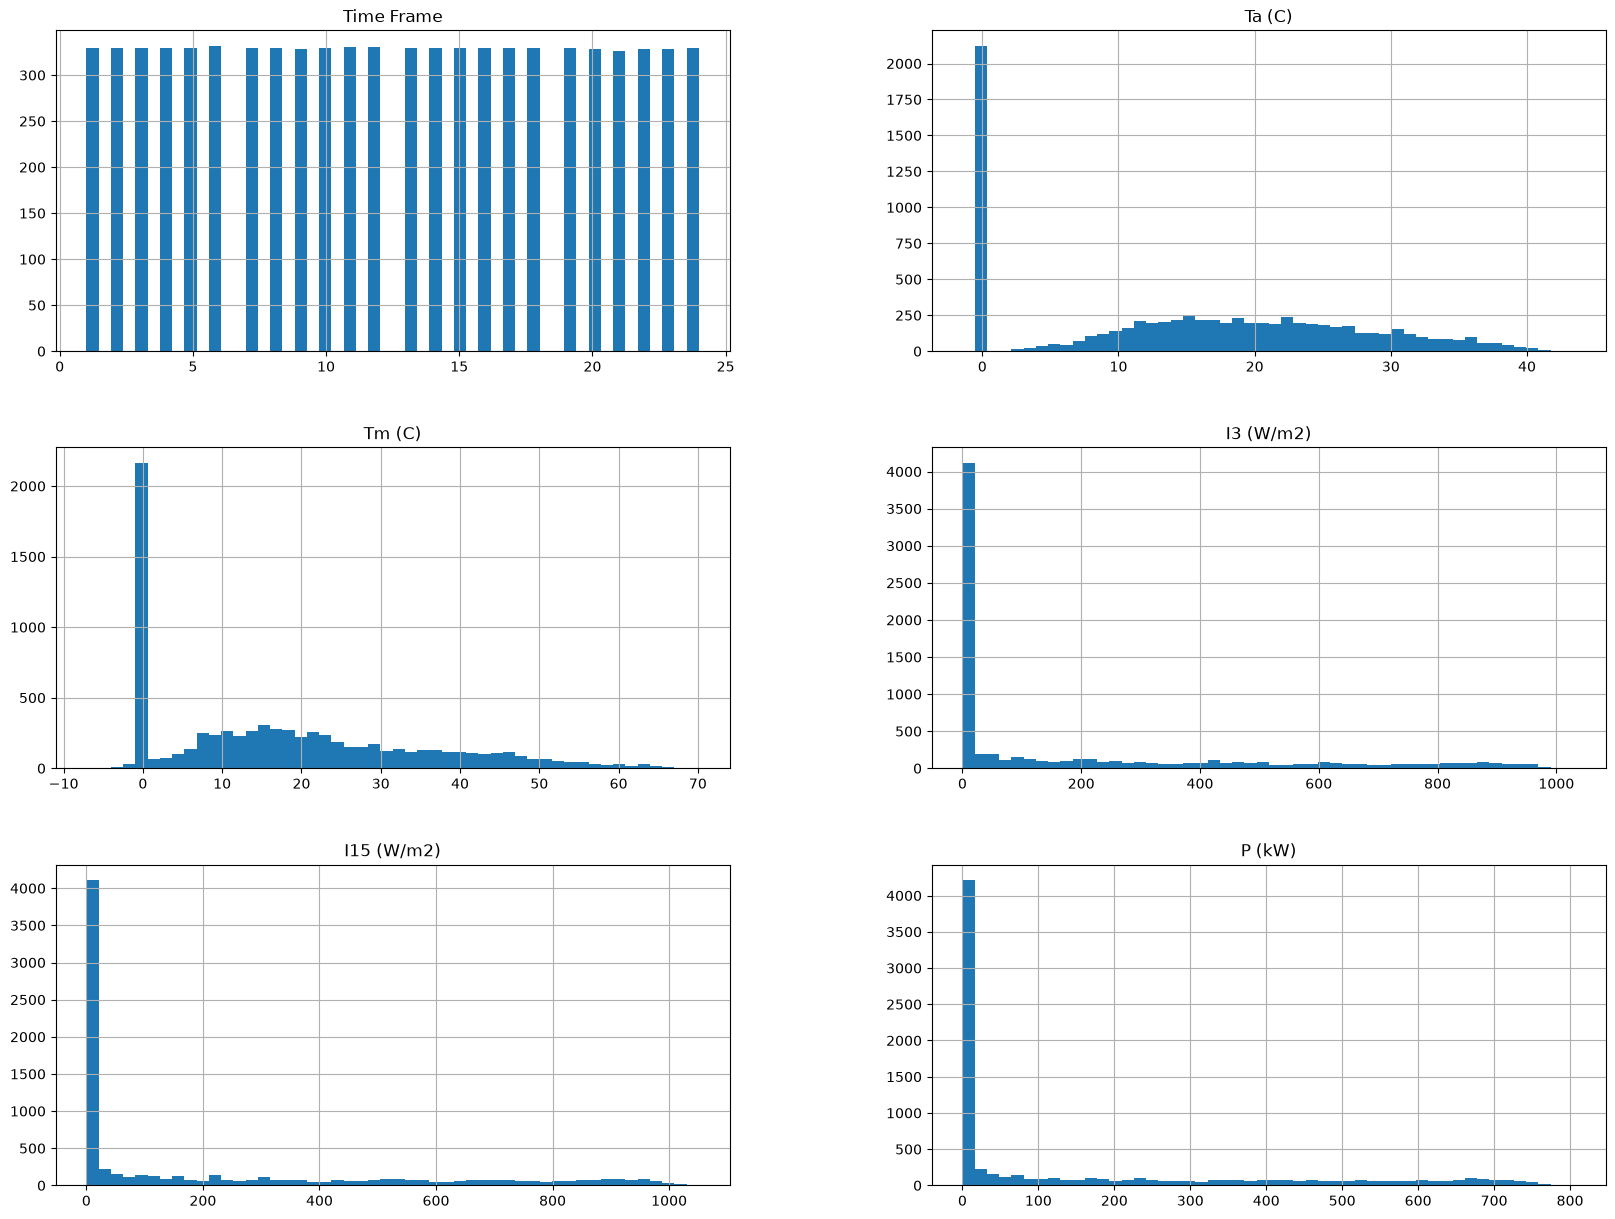

In [6]:
# Visualizzazione grafica della distribuzione dei valori delle features (istogrammi)
dataframe.hist(bins=50, figsize=(20,15))
plt.show()

Durante la prima analisi dei dati può essere utile individuare eventuali correlazioni tra le diverse feature. È possibile utilizzare il metodo **.corr()** per calcolare i coefficienti di correlazione. Nella cella seguente verranno stampati a video i coefficienti relativi alla correlazione tra le diverse feature rispetto all'etichetta "P (kW)".

In [7]:
# Calcolo dei coefficienti di correlazione tra le features
corr_matrix = dataframe.corr(numeric_only=True)

# Stampa dei coefficienti di correlazione tra le features e "P (kW)"
print(corr_matrix["P (kW)"].sort_values(ascending = False))

P (kW)        1.000000
I3 (W/m2)     0.986053
I15 (W/m2)    0.985978
Tm (C)        0.720901
Ta (C)        0.565826
Time Frame   -0.176942
Name: P (kW), dtype: float64


## Preprocessing dei dati
I dati contenuti nel **DataFrame** appena caricato non possono essere usati direttamente per l'addestramento di un modello di Machine Learning: la presenza di feature eterogenee (stringhe, interi e numeri floating point) deve essere gestita attraverso un'opportuna fase di *preprocessing*. In questa fase si avrà anche la possibilità di estrarre maggiori informazioni dai dati composti (come le date).

Ad esempio, la cella seguente mostra come sia possibile gestire le date (attualmente memorizzate sotto forma di stringa) per ottenere informazioni significative. La conversione da stringa a oggetto **Timestamp** è demandata alla funzione **to_datetime(...)**.

In [8]:
# Ottiene la stringa Date (colonna 1) del primo pattern
datetime_str = dataframe.values[:,1][0]  
print('Stringa datetime:', datetime_str)

# Conversione da stringa a oggetto Timestamp
datetime = pd.to_datetime(datetime_str, format='%m/%d/%y %I:%M %p')
print(type(datetime))
print('Datetime nel formato "anno-mese-giorno orario":', datetime)

# Stampa di informazioni relative alla data
print('Giorno dell\'anno:', datetime.timetuple().tm_yday)
print('Mese dell\'anno:', datetime.month)
print('Ora del giorno:', datetime.hour)

Stringa datetime: 3/5/12 4:55 PM
<class 'pandas.Timestamp'>
Datetime nel formato "anno-mese-giorno orario": 2012-03-05 16:55:00
Giorno dell'anno: 65
Mese dell'anno: 3
Ora del giorno: 16


Per poter addestrare un modello di Machine Learning è necessario convertire i dati del **DataFrame** in valori numerici e memorizzarli in un **ndarray**. Durante questa procedura sarà possibile estrarre maggiori informazioni, come visto nella cella precedente.

La cella successiva converte il **DataFrame** iniziale in un **ndarray** e opzionalmente esegue alcune operazioni per estrarre alcune informazioni aggiuntive dalla data.

Si noti l'uso dell'operatore [**_c\[...\]**](https://docs.scipy.org/doc/numpy/reference/generated/numpy.c_.html): questo permette di concatenare più **ndarray** ottenendone uno nuovo che contiene lo stesso numero di righe ma le cui colonne sono la concatenazione di quelle degli **ndarray** originali. Per comparazione, [**concatenate(...)**](https://docs.scipy.org/doc/numpy/reference/generated/numpy.concatenate.html) invece permette di concatenare più **ndarray** per riga.

In [ ]:
include_time_data = True

if include_time_data:
    datetime_strings = dataframe.values[:,1]
    
    # Converte tutte le stringhe in oggetti Timestamp
    datetimes = [pd.to_datetime(datetime, format='%m/%d/%y %I:%M %p') for datetime in datetime_strings]
    
    # Estrae alcune informazioni dagli oggetti Timestamp
    month = [datetime.month for datetime in datetimes]  # Meglio usare il mese se split temporale sequenziale
    yday = [datetime.timetuple().tm_yday for datetime in datetimes]  # Giorno dell'anno (se split random)
    # print(month)
    # print(yday)

# feature_x conterrà tutti i campi (esclusi Time Frame, Data e Potenza prodotta)
# Reminder: colonna 0 = Time Frame, colonna 1 = date, colonna 6 = potenza prodotta
feature_x = dataframe.values[:,2:6]

# Se include_time_data è True, include nel dataset anche le features relative alla data
# Nota: come orario è meglio utilizzare l'ordinale della colonna Time Frame (evita alcuni errori sui dati)
if include_time_data:
    feature_x = np.c_[feature_x, dataframe.values[:,0]] # Include solamente il Time Frame
    # feature_x = np.c_[feature_x, dataframe.values[:,0], month] # Include il Time Frame e il mese
    feature_x = np.c_[feature_x, dataframe.values[:,0], yday] # Include il Time Frame e il giorno dell'anno
    
# Estrae le etichette dal dataframe
feature_y = dataframe.values[:,6]   # Colonna 6: "P (kW)"

# Cast di tutti i valori a float32
feature_x = feature_x.astype(np.float32)
feature_y = feature_y.astype(np.float32)

# Alcune stampe di riepilogo
print('Shape del dataset:', feature_x.shape)
print('Primo pattern del dataset:', feature_x[0])
print('Shape delle etichette:', feature_y.shape)
print('Etichetta del primo pattern:', feature_y[0])

Shape del dataset: (7902, 7)
Primo pattern del dataset: [13.01 12.05 52.47 53.08 16.   16.   65.  ]
Shape delle etichette: (7902,)
Etichetta del primo pattern: 6.5


## Predizione all'ora successiva
In base al task da risolvere può essere richiesto di predire la quantità di energia prodotta nella stessa ora (ovvero l'etichetta dello stesso pattern) oppure di predire l'energia prodotta nell'ora successiva (ovvero l'etichetta del pattern successivo). Quest'ultimo scenario (*predict\_ahead*) risulta più interessante e può essere gestito assegnando a ogni pattern l'etichetta del pattern successivo.

Si noti come fino a questo punto i pattern del dataset non siano stati mescolati. In questa maniera è possibile modificare il dataset per allineare ogni pattern all'etichetta del pattern successivo utilizzando le istruzioni contenute nella seguente cella (in questo caso l'ultimo pattern verrà eliminato dal dataset).

In [10]:
# Se predict_ahead è True i dati saranno preparati per lo scenario "predict_ahead"
predict_ahead = True

if predict_ahead:
    # Sfasa i dati: le prediction sono quelle dell'ora successiva
    data_x = feature_x[0:-1,:]
    data_y = feature_y[1:]
else:
    data_x = feature_x
    data_y = feature_y

print(len(data_x), len(data_y))    
# Nota: sfasando i dati si perde l'ultimo pattern

7901 7901


## Split validation set
È possibile suddividere il dataset originale in train e validation set secondo due differenti strategie:
- la suddivisione casuale consiste nel selezionare casualmente i pattern da inserire nei due differenti set;
- la suddivisione temporale consiste nel suddividere il set originale in due parti non sovrapposte temporalmente.

Considerato che i pattern sono ordinati temporalmente, è possibile eseguire la seconda strategia operando un semplice *slicing* dei dati.

In [11]:
valid_portion = 0.5
split_random = False

if split_random:
    # Split casuale di train e validation set
    train_x, validation_x, train_y, validation_y = train_test_split(data_x, data_y, test_size=valid_portion, random_state=1)
else:    
    # Split temporale
    train_x, validation_x, train_y, validation_y = train_test_split(data_x, data_y, test_size=valid_portion, shuffle=False)

# Regressione in Scikit-Learn
L'obiettivo è quello di predire la quantità di energia prodotta in una certa fascia oraria (o in quella immediatamente successiva). La libreria Scikit-learn mette a disposizione diversi algoritmi per la regressione. Durante questa esercitazione verrà fatto uso di [**LinearRegression**](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) e di [**RandomForestRegressor**](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).

Queste classi condividono la API con quella dei classificatori. Pertanto, per addestrare un'istanza di un regressore sarà sufficiente richiamare il metodo **.fit(...)** mentre per ottenere le predizioni sarà necessario richiamare il metodo **.predict(...)**. L'obiettivo è quello di minimizzare l'RMSE, ovvero lo scostamento tra il valore predetto e quello reale.

Nella cella seguente è fornito il codice per creare e addestrare un'istanza di [**LinearRegression**](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).

In [12]:
# Addestramento di un LinearRegression
lin_reg = LinearRegression()
lin_reg.fit(train_x, train_y)

# Ottenimento delle predizioni
train_y_predicted = lin_reg.predict(train_x)

# Calcolo del RMSE
rmse = np.sqrt(mean_squared_error(train_y, train_y_predicted))
print('Train RMSE: ', rmse) 

# Ottenimento delle predizioni (validation) e calcolo RMSE
validation_y_predicted = lin_reg.predict(validation_x)
rmse = np.sqrt(mean_squared_error(validation_y, validation_y_predicted))
print('Validation RMSE: ', rmse)

Train RMSE:  98.61585033603878
Validation RMSE:  88.05937272658714


Allo stesso modo è possibile creare e addestrare un [**RandomForestRegressor**](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).

In [13]:
# Addestramento di un RandomForestRegressor
forest_reg = RandomForestRegressor(n_estimators=10)   
forest_reg.fit(train_x, train_y)

# Ottenimento delle predizioni
train_y_predicted = forest_reg.predict(train_x)

# Calcolo del RMSE
rmse = np.sqrt(mean_squared_error(train_y, train_y_predicted))
print('Train RMSE: ', rmse)

# Ottenimento delle predizioni (validation) e calcolo RMSE
validation_y_predicted = forest_reg.predict(validation_x)
rmse = np.sqrt(mean_squared_error(validation_y, validation_y_predicted))
print('Validation RMSE: ', rmse)

Train RMSE:  29.628137797172865
Validation RMSE:  104.32946436780485


In [14]:
# Addestramento di un SVR
svm_reg = SVR()   
svm_reg.fit(train_x, train_y)

# Ottenimento delle predizioni
train_y_predicted = svm_reg.predict(train_x)

# Calcolo del RMSE
rmse = np.sqrt(mean_squared_error(train_y, train_y_predicted))
print('Train RMSE: ', rmse)

# Ottenimento delle predizioni (validation) e calcolo RMSE
validation_y_predicted = svm_reg.predict(validation_x)
rmse = np.sqrt(mean_squared_error(validation_y, validation_y_predicted))
print('Validation RMSE: ', rmse)

Train RMSE:  114.72557604885972
Validation RMSE:  81.72240041151551


La funzione **.score(...)**, presente anche nella API degli *estimator*, restituisce un punteggio riguardante la capacità del classificatore/regressore nel predire i valori corretti. Per i classificatori questa funzione restitusce l'accuratezza sul dataset dato. Per i regressori restituisce il coefficiente $R^{2}$, ovvero un valore compreso tra 0 e 1 tanto più alto quanto è migliore la predizione restituita. Il valore di $R^{2}$ è statisticamente valido solo per regressione lineare.

In [15]:
print('R2 score:', lin_reg.score(validation_x, validation_y))

R2 score: 0.7728601694107056


A partire dalle predizione ottenuta nella cella precedente è possibile visualizzare la distribuzione degli errori sul validation set:

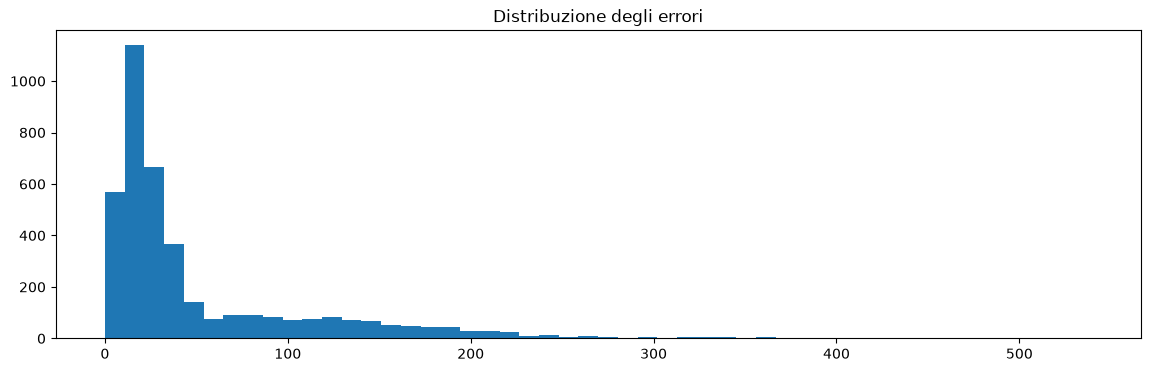

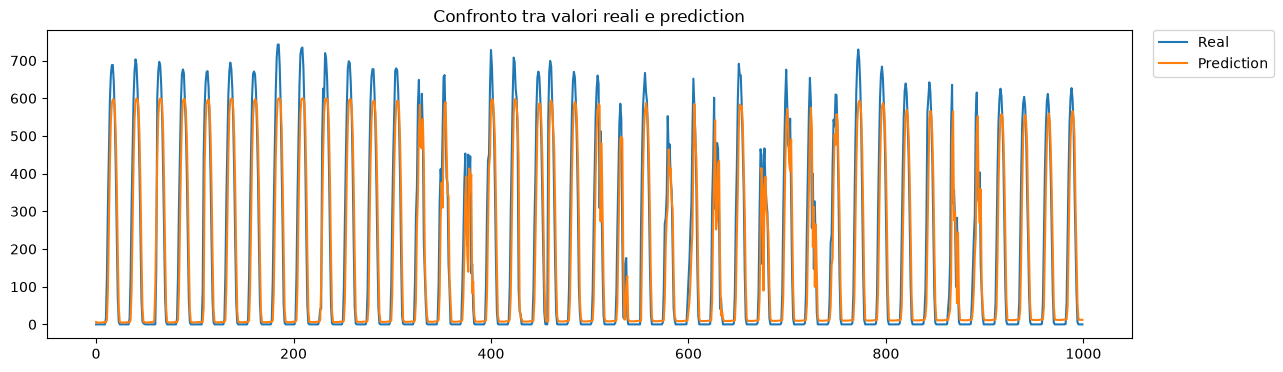

In [16]:
# Calcola l'errore come scostamento delle predizioni dal valore reale
errors = np.abs(validation_y - validation_y_predicted) 

plt.figure(figsize=(14, 4))
plt.title("Distribuzione degli errori")
plt.hist(x = errors, bins=50)
plt.show()

# Visualizza l'andamento reale e quello predetto
plt.figure(figsize=(14, 4))
plt.title("Confronto tra valori reali e prediction")
plt.plot(validation_y[0:1000], label='Real')
plt.plot(validation_y_predicted[0:1000], label='Prediction')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)
plt.show()

In [ ]:
# Data Cleaning

#print(dataframe.values[0])
#print(dataframe.values[0][0])
#print(pd.to_datetime(dataframe.values[0][1], format='%m/%d/%y %I:%M %p').hour)
#print(dataframe.values[0][0] == pd.to_datetime(dataframe.values[0][1], format='%m/%d/%y %I:%M %p').hour)

destination_path = "./DBs/SolarPark/clean_train.txt"
filePath = './DBs/SolarPark/train.txt'

dataframe = pd.read_csv(filePath)

clean_y = dataframe.values[:,6]   # Colonna 6: "P (kW)"
clean_x = dataframe.values[:,0:6]

clean_ahead_x = clean_x[0:-1,:]
clean_ahead_y = clean_y[1:]

# remove all the patterns with wrong time readings (time frame differend from datetime hour)
with open(destination_path, "a") as f:
     for i in range(0,len(clean_ahead_x)):
         row_hour = pd.to_datetime(clean_ahead_x[i][1], format='%m/%d/%y %I:%M %p').hour
         if clean_ahead_x[i][0] == row_hour:
             f.write(",".join(map(str, clean_ahead_x[i])) + "," + str(clean_ahead_y[i]) + "\n")

In [ ]:
# Ottimizzazione con Cross-Validation

regressors = {
    'names': [
        'Linear Regressor',
        'Random Forest Regressor',
        'Support Vector Machine'
    ],
    'reg':[
        LinearRegression(),
        RandomForestRegressor(),
        SVR()
    ],
    'gridSearch':[
        {
        },
        {
            'n_estimators': np.linspace(200,350,10).astype(int),
            'max_features': ['sqrt', 0.3, 0.5],
            'min_samples_leaf': [1,3,5,10],
        },
        {
            'C': [0.1, 1, 10 ,100, 1000],
            'gamma': ['scale', 'auto'] + list(np.logspace(-4, 0, 5)),
            'epsilon':[0.5,1,1.5,2]
        }
    ]
}

def train_regressor(regressors, f_train_x, f_train_y):
    results = []
    tscv = TimeSeriesSplit(n_splits=5)
    for i in range(0,len(regressors['reg'])):
        grid = GridSearchCV(
            estimator=regressors['reg'][i],
            param_grid=regressors['gridSearch'][i],
            #cv=tscv,
            scoring="neg_mean_squared_error",
            n_jobs=-1,
            refit=True
        )
        grid.fit(f_train_x, f_train_y)

        print("Best params for", regressors['names'][i],": :", grid.best_params_)
        print("Best score CV for", regressors['names'][i], ":", grid.best_score_)
        results.append(grid.best_estimator_)
    return results
    

In [ ]:
filePath = './DBs/SolarPark/clean_train.txt'
dataframe_clean = pd.read_csv(filePath)

# Calcolo dei coefficienti di correlazione tra le features
corr_matrix = dataframe_clean.corr(numeric_only=True)

# Stampa dei coefficienti di correlazione tra le features e "P (kW)"
print(corr_matrix["P (kW)"].sort_values(ascending = False))

include_time_data = True

if include_time_data:
    datetime_strings = dataframe_clean.values[:,1]
    
    # Converte tutte le stringhe in oggetti Timestamp
    datetimes = [pd.to_datetime(datetime, format='%m/%d/%y %I:%M %p') for datetime in datetime_strings]
    
    # Estrae alcune informazioni dagli oggetti Timestamp
    month = [datetime.month for datetime in datetimes]  # Meglio usare il mese se split temporale sequenziale
    yday = [datetime.timetuple().tm_yday for datetime in datetimes]  # Giorno dell'anno (se split random)
    # print(month)
    # print(yday)

# feature_x conterrà tutti i campi (esclusi Time Frame, Data e Potenza prodotta)
# Reminder: colonna 0 = Time Frame, colonna 1 = date, colonna 6 = potenza prodotta
feature_x = dataframe_clean.values[:,2:6]

# Se include_time_data è True, include nel dataset anche le features relative alla data
# Nota: come orario è meglio utilizzare l'ordinale della colonna Time Frame (evita alcuni errori sui dati)
if include_time_data:
    feature_x = np.c_[feature_x, dataframe_clean.values[:,0]] # Include solamente il Time Frame
    # feature_x = np.c_[feature_x, dataframe.values[:,0], month] # Include il Time Frame e il mese
    feature_x = np.c_[feature_x, dataframe_clean.values[:,0], yday] # Include il Time Frame e il giorno dell'anno
    
# Estrae le etichette dal dataframe
feature_y_clean = dataframe_clean.values[:,6]   # Colonna 6: "P (kW)"

# Cast di tutti i valori a float32
feature_x_clean = feature_x.astype(np.float32)
feature_y_clean = feature_y_clean.astype(np.float32)

# Alcune stampe di riepilogo
print('Shape del dataset:', feature_x.shape)
print('Primo pattern del dataset:', feature_x[0])
print('Shape delle etichette:', feature_y.shape)
print('Etichetta del primo pattern:', feature_y[0])

P (kW)        1.000000
I15 (W/m2)    0.912424
I3 (W/m2)     0.901798
Tm (C)        0.573069
Ta (C)        0.372223
Time Frame   -0.429182
Name: P (kW), dtype: float64
Shape del dataset: (5856, 7)
Primo pattern del dataset: [13.01 12.05 52.47 53.08 16 16 65]
Shape delle etichette: (7902,)
Etichetta del primo pattern: 6.5


In [29]:
results = train_regressor(regressors, feature_x_clean, feature_y_clean)

Best params for Linear Regressor : : {}
Best score CV for Linear Regressor : -10168.69609375
Best params for Random Forest Regressor : : {'criterion': 'squared_error', 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': np.int64(328)}
Best score CV for Random Forest Regressor : -5850.73631062038
Best params for Support Vector Machine : : {'C': 100, 'epsilon': 0.5, 'gamma': np.float64(0.0001), 'kernel': 'rbf'}
Best score CV for Support Vector Machine : -9876.481565951228


In [31]:
valid_portion = 0.5
split_random = False

if split_random:
    # Split casuale di train e validation set
    train_x, val_x, train_y, val_y = train_test_split(
        feature_x_clean, feature_y_clean,
        test_size=valid_portion, random_state=1)
else:
    # Split temporale
    train_x, val_x, train_y, val_y = train_test_split(
        feature_x_clean, feature_y_clean,
        test_size=valid_portion, shuffle=False)

svm_reg = SVR()
svm_reg.fit(train_x, train_y)

# Predizioni e RMSE sul train set
train_y_predicted = svm_reg.predict(train_x)
rmse = np.sqrt(mean_squared_error(train_y, train_y_predicted))
print('Train RMSE: ', rmse)

# Predizioni e RMSE sul validation set
validation_y_predicted = svm_reg.predict(val_x)
rmse = np.sqrt(mean_squared_error(val_y, validation_y_predicted))
print('Validation RMSE: ', rmse)

Train RMSE:  125.67626257902562
Validation RMSE:  89.68695520591233


# Test
Si addestri il regressore desiderato utilizzando gli iperparametri trovati nell'esercizio precedente. Il codice contenuto nella cella seguente userà tale regressore per predire la potenza prodotta nell'ora successiva a partire dai pattern del dataset di test. I valori predetti verranno memorizzati su un file di testo che dovrà essere caricato sul sito della competizione per misurarne l'RMSE.

In [ ]:
# Esercizio 2: valutazione su test set

train_path = './DBs/SolarPark/train.txt'
test_path = './DBs/SolarPark/test.txt'
result_path = 'Es5Predictions.txt'

# Caricamento dei pattern di train
train_dataframe = pd.read_csv(train_path)
# ...

# Estrazione delle informazioni dagli oggetti Timestamp
train_month = [datetime.month for datetime in ...]
# ...

# Cast di tutti i valori a float32
# ...

# Caricamento dei pattern di test
# Ricordarsi che i valori della colonna 6 (y) non sono disponibili!
test_dataframe = pd.read_csv(test_path)
# ...

# Estrazione delle informazioni dagli oggetti Timestamp
test_month = [datetime.month for datetime in ...]
# ...

# Cast di tutti i valori a float32
# ...

# Creazione e addestramento del classificatore
reg = ... 

print('Addestramento in corso ...')
reg.fit(train_x, train_y)

# Salvataggio delle predictions
predictions = reg.predict(test_x)
np.savetxt(result_path, predictions)
print('Ok')

TypeError: 'ellipsis' object is not iterable